# Homework 1: personal top-10 recommendations

**Student:** Гришанова Арина Вадимовна  
**Dataset:** [Amazon Reviews 2023, Software](https://amazon-reviews-2023.github.io/) by McAuley Lab.  
**Task:** recommend software products that a user would rate at least 4 stars.

Run from the repository root after `python -m pip install -r requirements.txt`.
The first cell downloads the two official source files into ignored `data/` if necessary.
The full run uses a fixed seed and takes several minutes on a laptop. All models below
are implemented in `models/`; no prebuilt recommender or learning algorithm is used.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from hashlib import sha256
from time import perf_counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, RatingTargetIALS

SEED = 42
np.random.seed(SEED)
DATA = Path('data')
DATA.mkdir(exist_ok=True)
SOURCE = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/'
FILES = {
    'Software.csv': (
        'benchmark/5core/rating_only/Software.csv',
        '6538476c9cb20fc983a829d06be796b1929be4f10171b1d551899caf5b3e0590',
    ),
    'meta_Software.jsonl': (
        'raw/meta_categories/meta_Software.jsonl',
        '7c52cce1bf3bff33f965fe117e3e8fac18a1839f88b215efa50b31a8230a5f58',
    ),
}
for name, (relative_url, expected_hash) in FILES.items():
    path = DATA / name
    if not path.exists():
        print('Downloading', name)
        urlretrieve(SOURCE + relative_url, path)
    digest = sha256(path.read_bytes()).hexdigest()
    assert digest == expected_hash, f'Checksum mismatch: {name}'
print('Source files are present and checksums match.')

Source files are present and checksums match.


## 1. Data and sampling

Each CSV row is a user review of one software product: `user_id`, `parent_asin`,
`rating` (1-5) and `timestamp` (Unix milliseconds). The metadata file supplies
catalog title, store and category. Missing interactions are **unknown**, not dislikes.
The source 5-core file contains about 1.28 million reviews. We select products
and users only from events before **2016-04-01**, then retain later reviews for
validation and test. This makes EASE practical without inspecting future popularity.

In [2]:
TRAIN_END = pd.Timestamp('2016-04-01', tz='UTC').value // 10**6
VALID_END = pd.Timestamp('2017-01-01', tz='UTC').value // 10**6
N_PRODUCTS = 1500
MIN_TRAIN_EVENTS = 8
MAX_USERS = 8000

raw = pd.read_csv(DATA / 'Software.csv')
raw_count = len(raw)
missing = raw.isna().sum()
raw = raw.dropna(subset=['user_id', 'parent_asin', 'rating', 'timestamp'])
raw = raw[raw['rating'].between(1, 5)].copy()
raw = raw.sort_values(['timestamp', 'user_id', 'parent_asin'])
duplicates = int(raw.duplicated(['user_id', 'parent_asin']).sum())
raw = raw.drop_duplicates(['user_id', 'parent_asin'], keep='first')

early = raw[raw.timestamp < TRAIN_END]
item_counts = early.groupby('parent_asin').size().reset_index(name='events')
item_counts = item_counts.sort_values(['events', 'parent_asin'], ascending=[False, True])
item_ids = sorted(item_counts.head(N_PRODUCTS).parent_asin)
selected = raw[raw.parent_asin.isin(item_ids)].copy()
user_counts = selected.loc[selected.timestamp < TRAIN_END].groupby('user_id').size()
eligible_users = user_counts[user_counts >= MIN_TRAIN_EVENTS]
user_ids = sorted(eligible_users.sort_values(ascending=False, kind='stable').head(MAX_USERS).index)
selected = selected[selected.user_id.isin(user_ids)].copy()
user_map = {key: index for index, key in enumerate(user_ids)}
item_map = {key: index for index, key in enumerate(item_ids)}
selected['user'] = selected.user_id.map(user_map).astype('int32')
selected['item'] = selected.parent_asin.map(item_map).astype('int32')
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

summary = pd.DataFrame({
    'stage': ['source file', 'after null/rating/dedup cleanup', 'final cohort'],
    'interactions': [raw_count, len(raw), len(selected)],
    'users': [pd.read_csv(DATA / 'Software.csv', usecols=['user_id']).user_id.nunique(),
              raw.user_id.nunique(), N_USERS],
    'items': [pd.read_csv(DATA / 'Software.csv', usecols=['parent_asin']).parent_asin.nunique(),
              raw.parent_asin.nunique(), N_ITEMS],
})
display(summary)
print('Missing fields:', missing.to_dict(), '| duplicate user-item pairs:', duplicates)
assert 100_000 <= len(selected) <= 2_000_000
assert N_USERS >= 1000 and N_ITEMS >= 1000

Missing fields: {'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0} | duplicate user-item pairs: 0


,stage,interactions,users,items
0,source file,1276840,146396,17591
1,after null/rating/dedup cleanup,1276840,146396,17591
2,final cohort,126617,8000,1500


In [3]:
selected_ids = set(item_ids)
metadata_rows = {}
with (DATA / 'meta_Software.jsonl').open(encoding='utf-8') as stream:
    for line in stream:
        row = json.loads(line)
        asin = row.get('parent_asin')
        if asin in selected_ids:
            metadata_rows[asin] = {
                'item': item_map[asin],
                'title': row.get('title') or '',
                'store': row.get('store') or '',
                'main_category': row.get('main_category') or '',
            }
metadata = pd.DataFrame(metadata_rows.values()).sort_values('item').reset_index(drop=True)
assert len(metadata) == N_ITEMS
print('Catalog field coverage:')
display((metadata[['title', 'store', 'main_category']] != '').mean().rename('nonempty share'))
display(metadata[['item', 'title', 'store', 'main_category']].head())

Catalog field coverage:


,nonempty share
title,1.0
store,1.0
main_category,1.0


,item,title,store,main_category
0,0,Microsoft Office Home and Student 2007 Old Version,Microsoft,Software
1,1,"OLD VERSION Microsoft Office Home and Student 2010 Family Pack, 3PC (Disc Version)",Microsoft,Software
2,2,Daily Bible,JoanSoft,Appstore for Android
3,3,TV Listings by TV24 - TV Guide,Jersey Productions,Appstore for Android
4,4,Kindle for Android,Amazon.com,Appstore for Android


## 2. EDA and temporal protocol

Popularity and user activity are long-tailed. We keep 1,500 most active **pre-cutoff**
products and the 8,000 most active users with at least eight pre-cutoff reviews. This avoids extremely
sparse histories while keeping more than the required 1,000 users/items and 100,000
interactions. It also narrows the task to warm-start, established products.

Matrix density: 0.009708916666666666


,split,rows,users,items,relevant_rows_rating_4_5
0,train,116507,8000,1500,84475
1,validation,4305,1966,794,3078
2,test,5805,2196,795,4156


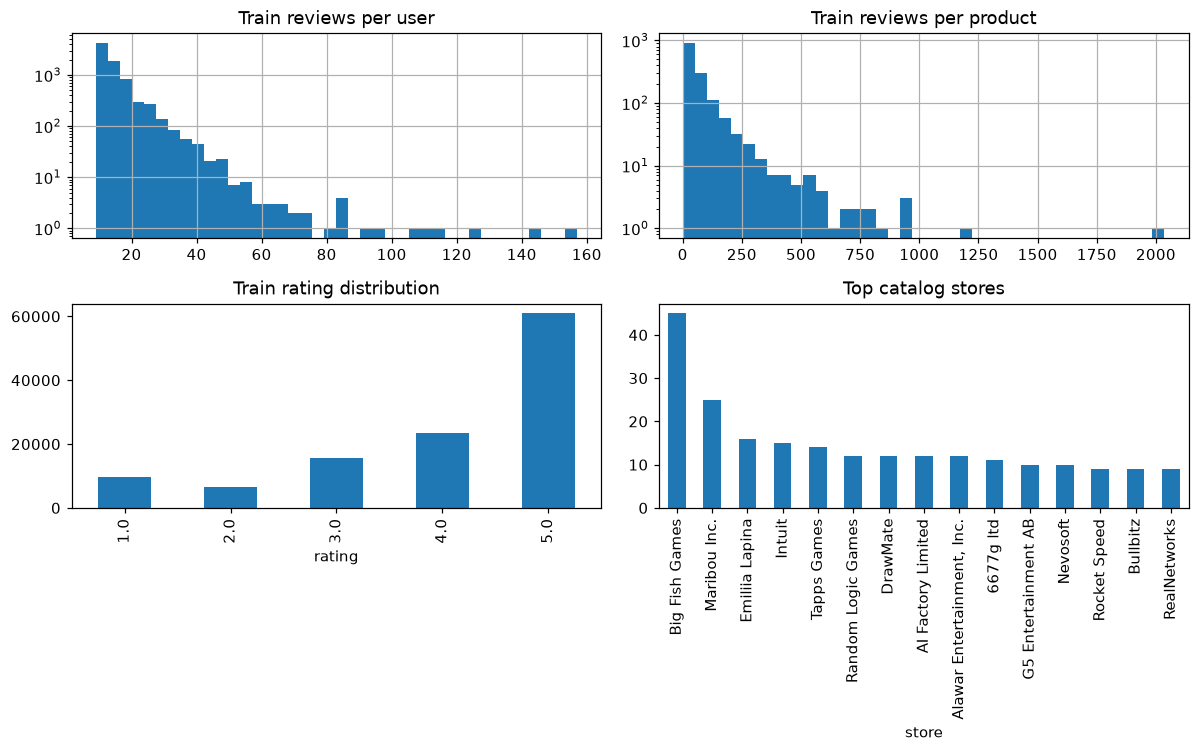

In [4]:
train = selected[selected.timestamp < TRAIN_END].copy()
valid = selected[(selected.timestamp >= TRAIN_END) & (selected.timestamp < VALID_END)].copy()
test = selected[selected.timestamp >= VALID_END].copy()
train_valid = pd.concat([train, valid], ignore_index=True)
split_summary = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'rows': [len(train), len(valid), len(test)],
    'users': [train.user.nunique(), valid.user.nunique(), test.user.nunique()],
    'items': [train.item.nunique(), valid.item.nunique(), test.item.nunique()],
    'relevant_rows_rating_4_5': [int((part.rating >= 4).sum()) for part in [train, valid, test]],
})
display(split_summary)
print('Matrix density:', len(train) / (N_USERS * N_ITEMS))
assert set(valid.user).issubset(set(train.user))
assert set(test.user).issubset(set(train.user))
assert set(valid.item).issubset(set(train.item))
assert set(test.item).issubset(set(train.item))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
train.groupby('user').size().hist(ax=axes[0, 0], bins=40, log=True)
axes[0, 0].set_title('Train reviews per user')
train.groupby('item').size().hist(ax=axes[0, 1], bins=40, log=True)
axes[0, 1].set_title('Train reviews per product')
train.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0])
axes[1, 0].set_title('Train rating distribution')
metadata.store.value_counts().head(15).plot.bar(ax=axes[1, 1])
axes[1, 1].set_title('Top catalog stores')
fig.tight_layout()
plt.show()

## 3. Shared top-10 evaluation

**Relevant** means a held-out rating of 4 or 5. The candidate set is all 1,500
products seen in training, with no negative sampling at evaluation. At validation
we exclude all training interactions; at test we exclude train + validation
interactions. Every model gets the same users, candidates and labels. Users with
no relevant held-out item are not included in the mean. Primary tuning metric:
**NDCG@10**, which rewards high positions. **Recall@10** measures the fraction
of relevant held-out products retrieved. Cold users/items are excluded by the
pre-cutoff cohort rule; a production system would need popularity/content fallback.

In [5]:
def history_matrix(frame):
    matrix = sparse.csr_matrix(
        (np.ones(len(frame), dtype=np.float32), (frame.user, frame.item)),
        shape=(N_USERS, N_ITEMS),
    )
    matrix.data[:] = 1
    return matrix


train_history = history_matrix(train)
train_valid_history = history_matrix(train_valid)


def evaluate(model, holdout, known):
    relevant = holdout.loc[holdout.rating >= 4].groupby('user').item.agg(list)
    users = relevant.index.to_numpy(dtype=np.int32)
    if len(users) == 0:
        raise ValueError('No relevant users in evaluation split')
    top = model.recommend(users, k=10, exclude=known)
    assert top.shape == (len(users), 10)
    recalls, ndcgs = [], []
    for row, truth in enumerate(relevant):
        truth = set(truth)
        hits = np.array([item in truth for item in top[row]], dtype=np.float64)
        recalls.append(hits.sum() / len(truth))
        discounts = 1 / np.log2(np.arange(2, 12))
        ideal = discounts[:min(len(truth), 10)].sum()
        ndcgs.append((hits * discounts).sum() / ideal)
    return {
        'Recall@10': float(np.mean(recalls)),
        'NDCG@10': float(np.mean(ndcgs)),
        'coverage@10': len(np.unique(top)) / N_ITEMS,
        'evaluated_users': len(users),
    }


print('Validation users:', valid.loc[valid.rating >= 4, 'user'].nunique())
print('Test users:', test.loc[test.rating >= 4, 'user'].nunique())

Validation users: 1654
Test users: 1831


## 4. Five models and formulas

1. **ItemKNN:** binary history, cosine item similarity with shrinkage, top-neighbor
   truncation. Score: `s(u,j) = sum(i in history(u)) sim(i,j)`.
2. **iALS:** minimize `sum_ui c_ui (p_ui - x_u^T y_i)^2 + lambda (||X||^2 + ||Y||^2)`.
   For observed pairs `p=1, c=1+alpha`; for unseen pairs `p=0, c=1`.
3. **EASE:** minimize `||R-RB||_F^2 + lambda ||B||_F^2` with `diag(B)=0`.
4. **FM:** `score(z) = w0 + sum(w_j z_j) + sum(a<b) <v_a,v_b> z_a z_b`.
   The binary training target is `rating >= 4`; one unknown item is sampled per
   positive review as a training-only negative proxy. Such pairs may include
   false negatives. Features include user/item IDs,
   title words, store and catalog category. Only static-looking catalog fields
   are used, never review aggregates, later ratings or `bought_together`.
5. **RatingTargetIALS:** the same ALS objective and confidence as (2), but for
   observed ratings `p_ui = clip((rating_ui - 3) / 2, 0, 1)`. Thus 1-3 stars give
   0, 4 stars give 0.5 and 5 stars give 1. This changes the **target**, not only
   confidence. Both ALS variants use the identical evaluation protocol.

All learners implement their own fit/predict logic. SciPy is used only for sparse
matrices and linear algebra, not as a ready-made recommender.

In [6]:
GRID = {
    'ItemKNN': [
        {'neighbors': 50, 'shrinkage': 10.0},
        {'neighbors': 150, 'shrinkage': 20.0},
    ],
    'iALS': [
        {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
        {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
    ],
    'EASE': [
        {'regularization': 100.0},
        {'regularization': 500.0},
    ],
    'FM': [
        {'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001,
         'epochs': 4, 'batch_size': 4096, 'seed': SEED},
        {'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001,
         'epochs': 4, 'batch_size': 4096, 'seed': SEED},
    ],
    'RatingTargetIALS': [
        {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
        {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
    ],
}


def make_model(name, params, use_metadata=True):
    cls = {'ItemKNN': ItemKNN, 'iALS': ImplicitALS, 'EASE': EASE,
           'FM': FactorizationMachine, 'RatingTargetIALS': RatingTargetIALS}[name]
    if name == 'FM':
        return cls(**params, use_metadata=use_metadata)
    return cls(**params)


def fit_model(model, data):
    if isinstance(model, FactorizationMachine):
        return model.fit(data, N_USERS, N_ITEMS, metadata)
    return model.fit(data, N_USERS, N_ITEMS)


validation_rows = []
for name, configurations in GRID.items():
    for params in configurations:
        start = perf_counter()
        model = fit_model(make_model(name, params), train)
        metrics = evaluate(model, valid, train_history)
        validation_rows.append({'model': name, 'params': params,
                                'fit_seconds': round(perf_counter() - start, 1), **metrics})
        print(name, params, 'NDCG@10 =', round(metrics['NDCG@10'], 4))
validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]))
chosen = (validation_results.sort_values(['NDCG@10', 'Recall@10'], ascending=False)
          .drop_duplicates('model').set_index('model'))
print('Chosen only from validation:')
display(chosen[['params', 'Recall@10', 'NDCG@10']])

ItemKNN {'neighbors': 50, 'shrinkage': 10.0} NDCG@10 = 0.0724
ItemKNN {'neighbors': 150, 'shrinkage': 20.0} NDCG@10 = 0.0725
iALS {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 = 0.0575
iALS {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 = 0.0528
EASE {'regularization': 100.0} NDCG@10 = 0.0765
EASE {'regularization': 500.0} NDCG@10 = 0.0717
FM {'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42} NDCG@10 = 0.0311
FM {'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42} NDCG@10 = 0.0271
RatingTargetIALS {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 = 0.0512
RatingTargetIALS {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 = 0.0437
Chosen only from validation:


,model,params,fit_seconds,Recall@10,NDCG@10,coverage@10,evaluated_users
4,EASE,{'regularization': 100.0},0.4,0.130422,0.076511,0.406667,1654
5,EASE,{'regularization': 500.0},0.4,0.120969,0.071713,0.280000,1654
6,FM,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",0.8,0.055725,0.031090,0.013333,1654
7,FM,"{'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",1.9,0.052187,0.027068,0.013333,1654
1,ItemKNN,"{'neighbors': 150, 'shrinkage': 20.0}",0.2,0.116788,0.072476,0.413333,1654
0,ItemKNN,"{'neighbors': 50, 'shrinkage': 10.0}",0.2,0.117189,0.072446,0.529333,1654
8,RatingTargetIALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.091649,0.051189,0.210667,1654
9,RatingTargetIALS,"{'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.079816,0.043731,0.266000,1654
2,iALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.098082,0.057508,0.228000,1654
3,iALS,"{'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.3,0.091673,0.052762,0.310000,1654


,params,Recall@10,NDCG@10
model,,,
EASE,{'regularization': 100.0},0.130422,0.076511
ItemKNN,"{'neighbors': 150, 'shrinkage': 20.0}",0.116788,0.072476
iALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",0.098082,0.057508
RatingTargetIALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",0.091649,0.051189
FM,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",0.055725,0.031090


### Metadata ablation (validation only)

FM with the selected hyperparameters is compared with the same FM using only
user/item IDs. This is diagnostic and does not change the preselected test model.

In [7]:
fm_params = chosen.loc['FM', 'params']
fm_ids = fit_model(make_model('FM', fm_params, use_metadata=False), train)
fm_ids_valid = evaluate(fm_ids, valid, train_history)
display(pd.DataFrame([
    {'variant': 'FM with metadata', **validation_results.loc[
        (validation_results.model == 'FM') &
        (validation_results.params.map(str) == str(fm_params))
    ].iloc[0][['Recall@10', 'NDCG@10', 'coverage@10', 'evaluated_users']].to_dict()},
    {'variant': 'FM IDs only', **fm_ids_valid},
]).set_index('variant'))

,Recall@10,NDCG@10,coverage@10,evaluated_users
variant,,,,
FM with metadata,0.055725,0.031090,0.013333,1654
FM IDs only,0.047078,0.029921,0.016000,1654


## 5. Final test comparison

The configuration of each method was selected above using validation only.
Now each method is refit on train + validation and evaluated once on test.
All results use the same warm-start catalog and the same held-out users.

ItemKNN test NDCG@10 = 0.0578
iALS test NDCG@10 = 0.0547
EASE test NDCG@10 = 0.0635
FM test NDCG@10 = 0.0382
RatingTargetIALS test NDCG@10 = 0.0504


,model,Recall@10,NDCG@10,coverage@10,evaluated_users,fit_seconds,params
2,EASE,0.108277,0.063501,0.412000,1831,0.4,{'regularization': 100.0}
0,ItemKNN,0.098185,0.057835,0.421333,1831,0.2,"{'neighbors': 150, 'shrinkage': 20.0}"
1,iALS,0.089188,0.054709,0.239333,1831,1.2,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}"
4,RatingTargetIALS,0.081817,0.050439,0.215333,1831,1.2,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}"
3,FM,0.064220,0.038244,0.012667,1831,0.8,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}"


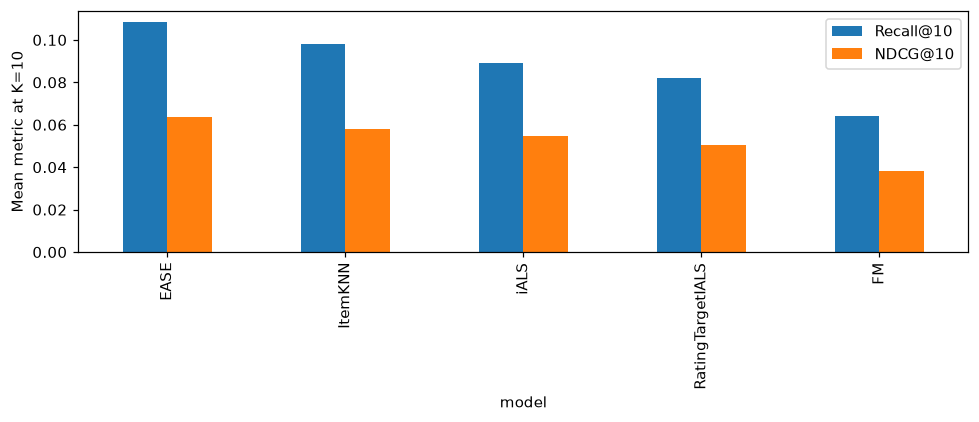

In [8]:
final_models = {}
test_rows = []
for name in GRID:
    params = chosen.loc[name, 'params']
    start = perf_counter()
    model = fit_model(make_model(name, params), train_valid)
    final_models[name] = model
    metrics = evaluate(model, test, train_valid_history)
    test_rows.append({'model': name, 'params': params,
                      'fit_seconds': round(perf_counter() - start, 1), **metrics})
    print(name, 'test NDCG@10 =', round(metrics['NDCG@10'], 4))
test_results = pd.DataFrame(test_rows).sort_values('NDCG@10', ascending=False)
display(test_results[['model', 'Recall@10', 'NDCG@10', 'coverage@10',
                      'evaluated_users', 'fit_seconds', 'params']])
ax = test_results.set_index('model')[['Recall@10', 'NDCG@10']].plot.bar(figsize=(9, 4))
ax.set_ylabel('Mean metric at K=10')
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## 6. Conclusions and limitations

The next cell prints the best method, the difference between the two ALS targets,
and the validation effect of metadata. These statements are generated from the
actual outputs above rather than fixed in advance. This is an offline study of
warm users and already-known products. It has no exposure logs, so unknown
interactions are not confirmed dislikes. The item metadata file is a later
catalog snapshot; title/store are treated as stable descriptors, but historical
versions are unavailable. This limits a strict historical claim about FM.
The source 5-core filtering also changes the original population before our
split. Results may differ for cold users/products and another time period.

In [9]:
best = test_results.iloc[0]
base = test_results.set_index('model').loc['iALS']
custom = test_results.set_index('model').loc['RatingTargetIALS']
meta_ndcg = float(chosen.loc['FM', 'NDCG@10'])
print(f"Best test NDCG@10: {best['model']} ({best['NDCG@10']:.4f}); "
      f"Recall@10 = {best['Recall@10']:.4f}.")
print(f"Rating-based target vs binary iALS on test: "
      f"delta NDCG@10 = {custom['NDCG@10'] - base['NDCG@10']:+.4f}, "
      f"delta Recall@10 = {custom['Recall@10'] - base['Recall@10']:+.4f}.")
print(f"FM metadata vs IDs only on validation: "
      f"delta NDCG@10 = {meta_ndcg - fm_ids_valid['NDCG@10']:+.4f}.")

Best test NDCG@10: EASE (0.0635); Recall@10 = 0.1083.
Rating-based target vs binary iALS on test: delta NDCG@10 = -0.0043, delta Recall@10 = -0.0074.
FM metadata vs IDs only on validation: delta NDCG@10 = +0.0012.


In this run, EASE leads on both NDCG@10 and Recall@10. ItemKNN is next;
both item-to-item methods seem to use co-occurring software products effectively.
The rating-based ALS target performed worse than binary iALS, so explicitly
lowering the target for 4-star reviews did not help here. Adding title/store/
category features improved FM slightly on validation, but FM's test catalog
coverage is very low: it concentrates recommendations on a small group of
products. Thus the metadata gain does not make FM competitive with EASE on
this warm-start sample. A broader candidate catalog or more diverse negative
sampling would be sensible next experiments, not claims from this test.